AI Lab - initial guidelines to generate your reports
This is a small sample notebook for you with some information that you might use to generate you reports. It has some guidelines, some initial ideas, and some questions for you to think about and discuss. This is only an initial notebook, please organize as you like.

I expect you to grow your notebooks into full project reports, with your work and results, the description of your steps, justification for your choices, and your ideas and considerations. Please use both text and visualisations to clarify results and concepts. Please try also to capture the discussion we had in class, and the discussion you had afterwards. The final reports should reflect the work of your group and your very own results, ideas and discussion.

If you need domain specific knowlegde you can check again some of the handouts, and you can also explore further some of the links in the handouts, or you can ask. However, please try not to be too domain specific in your thinking and in your reports, try to to apply the theory you have learnt and use your observations and results to extract general underlying concepts.

For the first AI Lab day we progress all together, and below I give you some more pointers for the first analysis steps. This is so you can familizarize with the data. After this, from day 2, you will progress more independently, and for days 3 and 4 you will divide into groups for the data challenge.

Introduction
Please include a short introduction based on what we discussed in class:

Background
Overall Aim
Specific Objectives
[...]

This should be based on what we discussed in class. Please ask any questions you have or clarifications, you can also consult the handouts. I would probably aim for no more than 200 words for this section.

Materials and Methods

Please include:

A short description of the data and how they were obtained.
A short description of the methods you will use and why.
[...]

I would aim for no longer than 300 words, but you could also provide more details and justification of data and methods when you load them/use them in the following sections.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Remember you can use command line mode if installations are needed
#!pip install numpy
#!pip install matplotlib
#!pip install seaborn
#!pip install pandas
#!pip install scikit-learn
#!pip uninstall umap
#!pip install umap-learn

import sys
import sklearn

# import umap
import matplotlib as mp
import matplotlib.pyplot
from sklearn.decomposition import PCA
#from umap.umap_ import UMAP
import seaborn as sns
import plotly as py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt             #visualisation
%matplotlib inline     
sns.set(color_codes=True)
#[....] for you to add

Exploratory data analysis
First we load the data. There are four datasets. They correspond to four different experiments in two different cell lines, and using two different single cell RNA sequencing techniques. You might proceed one experiment at a time, or download the metadata for all experiments and discuss them together. Here I show the example for one of the datasets.

MCF7 SmartSeq experiment
First we read in the metadata. There are 4 metadata files. One for each experiment. They are tab delimited file TSV.

In [ ]:
df_meta = pd.read_csv("MCF7_SmartS_MetaData.tsv",delimiter="\t",engine='python',index_col=0)
print("Dataframe dimensions:", np.shape(df_meta))
print("First column: ", df_meta.iloc[ : , 0])

Dataframe dimensions: (383, 8)
First column:  Filename
output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam      MCF7
output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam      MCF7
                                                            ... 
output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam    MCF7
Name: Cell Line, Length: 383, dtype: object


In [ ]:
df_meta.head(5)   

,Cell Line,Lane,Pos,Condition,Hours,Cell name,PreprocessingTag,ProcessingComments
Filename,,,,,,,,
output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A10,Hypo,72,S28,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A11,Hypo,72,S29,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A12,Hypo,72,S30,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A1,Norm,72,S1,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A2,Norm,72,S2,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"


Each row represents a single data entry, while columns represent different attributes: \\
Column 1: File names of aligned BAM files. \\
Column 2: Cell line information; in this case, MCF7 (derived from breast cancer cells). A cell line is a population of cells that are derived from a single cell or a small number of cells and have been cultured and propagated in vitro (in a laboratory setting) for experimental or research purposes \\
# Column 3: Information related to the STAR and FeatureCounts tools used for data analysis ***(?)***. 
Column 4: Sample names or identifiers. \\
Column 5: Treatment condition information. \\
Column 6: Could represent the amount of time that the samples were exposed to a particular experimental condition, treatment, or manipulation (72 hours, in this case). \\
Column 7: Cell name. \\
Column 8: "Aligned.sortedByCoord.out.bam" represents a file generated from an alignment step in a bioinformatics analysis pipeline. \\
Column 9: "STAR,FeatureCounts" indicates that both STAR and FeatureCounts software tools were used in the data analysis pipeline for processing the given dataset. \\

**Unfiltered Data**

In [ ]:
# Remember to change the path. This should point to where you have stored the data files. 
df = pd.read_csv("MCF7_SmartS_Unfiltered_Data.txt",delimiter="\ ",engine='python',index_col=0)
print("Dataframe dimensions:", np.shape(df))
print("First column: ", df.iloc[ : , 0])

Dataframe dimensions: (22934, 383)
First column:  "WASH7P"         0
"MIR6859-1"      0
"WASH9P"         1
"OR4F29"         0
"MTND1P23"       0
              ... 
"MT-TE"          4
"MT-CYB"       270
"MT-TT"          0
"MT-TP"          5
"MAFIP"          8
Name: "output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam", Length: 22934, dtype: int64


For each data file, describe its structure and content. \\

File dimensions \\
Rows represent different types of genes \\
Columns are different cells \\
Numbers represent how many times a gene is expressed in a cell\\
This dataframe uses Symbols to identify genes (e.g. You can add the discussion we had in class on identifiers) [...]


In [ ]:
print(df.shape) # How large the file is
print('Number of Samples:', df.shape[0])
print('Number of Features:', df.shape[1])

(22934, 383)
Number of Samples: 22934
Number of Features: 383


In [ ]:
df.head(5)  

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A7_Hypo_S25_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H2_Norm_S356_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"""
"""WASH7P""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,1
"""MIR6859-1""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""WASH9P""",1,0,0,0,0,1,10,1,0,0,...,1,1,0,0,0,0,1,1,4,5
"""OR4F29""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
"""MTND1P23""",0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [ ]:
list(df.columns)[0:10] # Names of the cells (only first 10)

['"output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A7_Hypo_S25_Aligned.sortedByCoord.out.bam"']

In [ ]:
df.index # Names of genes

Index(['"WASH7P"', '"MIR6859-1"', '"WASH9P"', '"OR4F29"', '"MTND1P23"',
       '"MTND2P28"', '"MTCO1P12"', '"MTCO2P12"', '"MTATP8P1"', '"MTATP6P1"',
       ...
       '"MT-TH"', '"MT-TS2"', '"MT-TL2"', '"MT-ND5"', '"MT-ND6"', '"MT-TE"',
       '"MT-CYB"', '"MT-TT"', '"MT-TP"', '"MAFIP"'],
      dtype='object', length=22934)

Exploratory data analysis include a broad range of possible tasks: \\

what can you observe by looking at the data (maybe use some plots to explain) \\

In [ ]:
df.dtypes

"output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam"      int64
"output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam"      int64
                                                              ...  
"output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"    int64
Length: 383, dtype: object

In [ ]:
# Check if all data types are numerical
is_numerical = all(df[col].dtype.kind in 'fi' for col in df.columns)

if is_numerical:
    print("All data types are numerical.")
else:
    print("Not all data types are numerical.")

All data types are numerical.


The aim is to understand the data by summarizing their main characteristics (e.g. tables with statistics or visually). This step is the very first one when we analyse the data. It can be time consuming but it is very useful to understand the data, perform some quality control, and define the downstream analysis. \\

Of note, there are ways of carrying out EDA and some steps that are domain specific, and even in the same domain sometimes there are different ways of carrying out EDA. It might depends on the specific technology or the specific question. However, most of the concepts are general and applicable to many contexts. The focus should be on the general context. \\

You have an "unfiltered" data file. These are data are matrixes of counts, no filter was applied and no normalization was applied. It is a good idea to start to explore this first to understand the issues with the dataset and discuss them, and what are the general implications of the issues you encounter. \\

You have also "filtered" data and "normalized" data. These have been pre-processed for you so eliminate some of the issues. You can use these to train your classifiers.

**Missing Values** \\
Checking for missing values.

In [ ]:
print(df.isnull().sum())

"output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam"      0
"output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam"      0
                                                             ..
"output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"    0
Length: 383, dtype: int64


In [ ]:
def null_percentage(col):
    possible_nulls = [None, np.nan, 'None', '?']
    null_count = col.isin(possible_nulls).sum()
    total_count = len(col)
    return round(null_count / total_count * 100)

# Calculate the percentage of null values in each column
df.apply(null_percentage)

"output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam"      0
"output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam"      0
                                                             ..
"output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"    0
Length: 383, dtype: int64

In [ ]:
df.isnull().sum().sum()

0

Since the sum of missing values of every cell is 0, we can state that there are no missing values.

**Duplicates**

Finding duplicate rows is useful because it can help identify and remove redundant or unnecessary data from the dataset. They can arise due to data entry errors, measurement errors, or other factors, and can lead to biased or misleading results if not handled properly. By removing duplicate rows, we can ensure that the dataset is clean, accurate, and representative of the underlying population. <br>
We start by checking if we have any duplicate genes (rows).

In [ ]:
duplicate_rows_tot = df.duplicated(keep=False).sum()
print(f"There are {duplicate_rows_tot} duplicate rows.")

There are 56 duplicate rows.


Now we want to understand which rows are the duplicates. We print them all.

In [ ]:
# Identify duplicate rows
duplicate_rows = df.duplicated(keep=False)

# Print the duplicate rows
print(df[duplicate_rows])

                   "output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"  \
"SHISAL2A"                                                         0            
"IL12RB2"                                                          0            
"S1PR1"                                                            0            
"CD84"                                                             0            
"GNLY"                                                             0            
"FAR2P3"                                                           0            
"KLF2P3"                                                           0            
"PABPC1P2"                                                         0            
"UGT1A8"                                                           0            
"UGT1A9"                                                           0            
"SLC22A14"                                                         0            
"COQ10BP2"                  

We have to note that when we remove one of the duplicate genes, we may lose important biological information. For example, the gene that has been removed could be the one that has been previously annotated or studied extensively in other studies. If we remove this gene without recording it in a log file, we could miss an important biological link between the current study and historical studies. We procede by creating a new dataframe where we store all the above found duplicates.

In [ ]:
# new dataframe containing all duplicate rows
duplicate_rows_df = df[df.duplicated(keep=False)]

Next step is understanding where exactly the duplicates are, meaning which genes are the duplicates of others. We calculate the correlation matrix which measures the linear relationship between pairs of genes across the duplicated rows. Each element of the correlation matrix represents the correlation coefficient between the expression values of two genes in the duplicated rows. The genes with correlation coefficient 1 are the duplicates.

In [ ]:
duplicate_rows_df_t = duplicate_rows_df.T
c_dupl = duplicate_rows_df_t.corr()

# Find the genes that have a correlation coefficient of 1
duplicate_genes = []
for gene_1 in c_dupl.index:
    for gene_2 in c_dupl.columns:
        if gene_1 != gene_2 and c_dupl.loc[gene_1, gene_2] == 1 and gene_1 not in duplicate_genes and gene_2 not in duplicate_genes:
            duplicate_genes.append(gene_1)
            print(f"{gene_1} and {gene_2} are duplicates")

"SHISAL2A" and "COQ10BP2" are duplicates
"IL12RB2" and "GALNT17" are duplicates
"S1PR1" and "MUC6" are duplicates
"CD84" and "WDR95P" are duplicates
"GNLY" and "KCNS2" are duplicates
"FAR2P3" and "KLF2P3" are duplicates
"PABPC1P2" and "SLC22A14" are duplicates
"UGT1A8" and "UGT1A9" are duplicates
"PANDAR" and "LAP3P2" are duplicates
"RPL22P16" and "RNA5SP450" are duplicates
"GALNT17" and "PON1" are duplicates
"HTR5A" and "RNU6-539P" are duplicates
"SNORA36A" and "MIR664B" are duplicates
"CSMD1" and "SEZ6L" are duplicates
"KCNS2" and "BCL6B" are duplicates
"MIR548AA1" and "MIR548D1" are duplicates
"MTCO2P11" and "CACYBPP1" are duplicates
"CLCN3P1" and "OTOP3" are duplicates
"SUGT1P4-STRA6LP" and "STRA6LP" are duplicates
"VSTM4" and "PSG1" are duplicates
"LINC00856" and "LINC00595" are duplicates
"LINC00477" and "KNOP1P1" are duplicates
"MIR20A" and "MIR19B1" are duplicates
"RPL21P5" and "RBFOX1" are duplicates
"SNRPN" and "SNURF" are duplicates
"LINC02183" and "ADAMTS5" are duplicates
"

In [ ]:
# pd.plotting.scatter_matrix(duplicate_rows_df_t, alpha=0.2, figsize=(10, 10))
# sns.pairplot(duplicate_rows_df_t, diag_kind='hist')
# since the plots take infinite time i din't think we should include them :)

Finally, we drop the duplicated genes keeping the first one of the duplicates that appears. Furthermore, we also create a list containing all the genes that are removed so that we have that information stored as well.

In [ ]:
# Create a list of gene names before dropping duplicates
genes_before_drop = list(df.index)

# Drop duplicates and keep track of removed genes
removed_genes = set()
df.drop_duplicates(keep='first', inplace=True)
for gene_1 in genes_before_drop:
    if gene_1 not in df.index:
        removed_genes.add(gene_1)

# Print the list of removed genes
print("Removed genes:", removed_genes)
# check the new size of dataframe to see if everything was done correctly
print(df.shape) 

Removed genes: {'"MIR19B1"', '"GALNT17"', '"SLC22A14"', '"CCL3L1"', '"KNOP1P1"', '"ASPA"', '"SEZ6L"', '"STRA6LP"', '"OTOP3"', '"ADAMTS5"', '"MIR3191"', '"PON1"', '"KLF2P3"', '"BCL6B"', '"CACYBPP1"', '"PSG1"', '"KCNS2"', '"WDR95P"', '"LINC00595"', '"MIR664B"', '"MUC6"', '"LAP3P2"', '"COQ10BP2"', '"UGT1A9"', '"MIR548D1"', '"RNU6-539P"', '"RBFOX1"', '"RNA5SP450"', '"SNURF"'}
(22905, 383)


In some cases, as a result of errors in data collection or processing, duplicated columns can appear as well. Having duplicated columns can cause problems in data analysis and modeling since they can introduce redundancy and skew the results. We proceed by checking if there are any.

In [ ]:
duplicate_cols = df.columns[df.transpose().duplicated()].tolist()

if duplicate_cols:
    print(f"The following columns are duplicated: {duplicate_cols}")
else:
    print("There are no duplicated columns.")

There are no duplicated columns.


**Correlation**

We will plot a heatmap of the correlation matrix, with cool and warm colors representing negative and positive correlations, respectively.

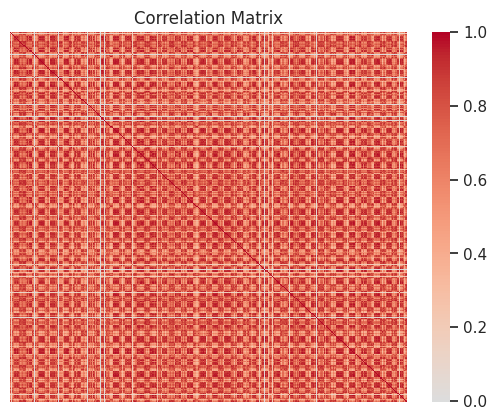

In [ ]:
# Compute the correlation matrix for all pairs of cells based on genes
corr_matrix = df.corr()

# Plot a heatmap of the correlation matrix
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation Matrix")
plt.show()

From the plot, we can see that the dark red color represents high correlation between two cells, which means that the cells have similar gene expression profiles; this could indicate that they have a similar cellular function or that they are part of the same cell population.

We then proceed to print the top 10 correlated cell pairs based on the correlation coefficient. \\
We use the unstack method of the correlation matrix to convert it to a long-format table with three columns: the row index (cell A), the column index (cell B), and the correlation coefficient between A and B. We then filter out self-correlations, and sort the remaining pairs by correlation coefficient in descending order. \\
The indices on the left indicate the position of each pair of correlated cells in the correlation matrix, starting from 0 for the first pair, 1 for the second pair, and so on.

In [ ]:
# Convert the correlation matrix to a long-format table
corr_table = corr_matrix.unstack().reset_index(name="correlation")
corr_table = corr_table.rename(columns={"level_0": "cell_1", "level_1": "cell_2"})

# Filter out self-correlations
corr_table = corr_table[corr_table["cell_1"] != corr_table["cell_2"]]
corr_table = corr_table[corr_table["cell_1"] < corr_table["cell_2"]]

# Sort the pairs by correlation coefficient in descending order
corr_table = corr_table.sort_values(by="correlation", ascending=False)

# Print the top 10 correlated gene pairs
print(corr_table.head(10))

# Interpret the correlation results
# For example, we can check the GO terms or pathways of the correlated genes
# and see if they share common functions or regulatory mechanisms.

                                                   cell_1  \
137089  "output.STAR.4_F7_Hypo_S283_Aligned.sortedByCo...   
39014   "output.STAR.2_A3_Norm_S9_Aligned.sortedByCoor...   
61095   "output.STAR.2_F1_Norm_S247_Aligned.sortedByCo...   
61179   "output.STAR.2_F1_Norm_S247_Aligned.sortedByCo...   
48612   "output.STAR.2_C4_Norm_S106_Aligned.sortedByCo...   
21154   "output.STAR.1_E5_Norm_S197_Aligned.sortedByCo...   
127128  "output.STAR.4_D5_Norm_S167_Aligned.sortedByCo...   
84099   "output.STAR.3_C1_Norm_S109_Aligned.sortedByCo...   
52693   "output.STAR.2_D3_Norm_S153_Aligned.sortedByCo...   
71569   "output.STAR.2_H4_Norm_S346_Aligned.sortedByCo...   

                                                   cell_2  correlation  
137089  "output.STAR.4_F8_Hypo_S284_Aligned.sortedByCo...     0.995504  
39014   "output.STAR.4_D5_Norm_S167_Aligned.sortedByCo...     0.989212  
61095   "output.STAR.3_A4_Norm_S16_Aligned.sortedByCoo...     0.986084  
61179   "output.STAR.3_H4_Norm_S352_

Check for linearity: Correlation coefficients measure linear relationships between variables, so it's important to check that the relationship between each pair of variables is roughly linear. If the relationship is nonlinear, the correlation coefficient may not accurately reflect the true association between the variables.

Check for multicollinearity: Multicollinearity occurs when two or more variables are highly correlated with each other. This can cause problems in statistical analysis, so it's important to check for multicollinearity in the correlation matrix and consider removing one of the highly correlated variables if necessary.

**Describe**

In [ ]:
df.describe()

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A7_Hypo_S25_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H2_Norm_S356_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"""
count,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,...,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000
mean,40.869330,0.012268,86.549356,1.025933,14.549749,56.284741,75.492556,62.847195,67.482078,2.243571,...,17.384545,42.133508,34.736302,32.775682,22.020563,17.461209,49.305086,61.623226,68.375769,62.930976
std,466.002411,0.207857,1037.224285,6.101112,123.877800,503.913891,430.735604,520.491980,459.973686,25.465612,...,193.275011,256.933843,680.390121,300.478924,153.536760,198.304138,359.560626,541.185241,637.290526,786.164389
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,17.000000,0.000000,5.000000,0.000000,7.000000,23.000000,39.000000,35.000000,38.000000,1.000000,...,9.000000,30.000000,0.000000,17.000000,12.000000,9.000000,27.000000,30.000000,38.000000,33.000000
max,46744.000000,14.000000,82047.000000,289.000000,10582.000000,46856.000000,29534.000000,50972.000000,36236.000000,1707.000000,...,17800.000000,23355.000000,81952.000000,29540.000000,12149.000000,19285.000000,28021.000000,40708.000000,46261.000000,68790.000000


**Variance of Genes** \\
By plotting the variances on a histogram, it can be noticed how almost every gene

In [ ]:
zero_variances = (df.var(axis=1) == 0).sum()
print(zero_variances)

0


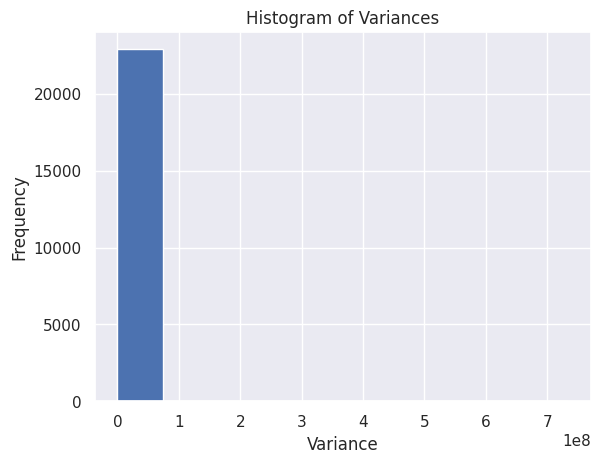

In [ ]:
# Calculate variances
variances = df.var(axis=1)

# Plot histogram of variances
plt.hist(variances)
plt.xlabel('Variance')
plt.ylabel('Frequency')
plt.title('Histogram of Variances')
plt.show()

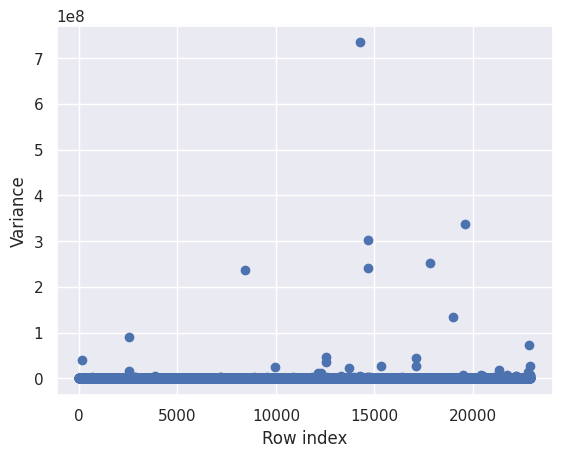

In [ ]:
# Calculate variances
variances = df.var(axis=1)

# Plot scatterplot of variances
plt.scatter(range(len(variances)), variances)
plt.xlabel('Row index')
plt.ylabel('Variance')
plt.show()

**Dimensionality Reduction**

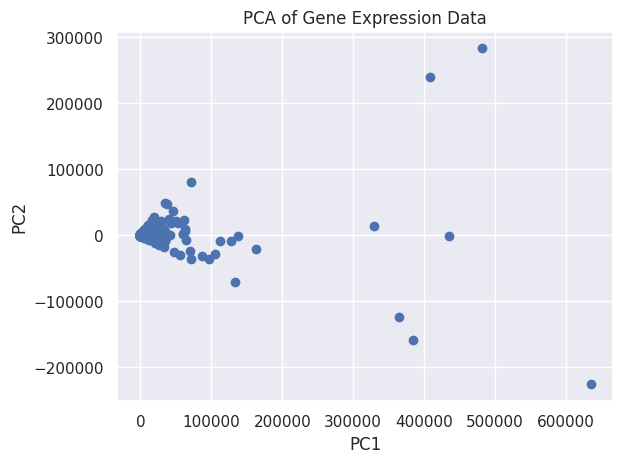

In [ ]:
# Normalize the data if needed

# Apply PCA
pca = PCA(n_components=2)  # Specify the number of principal components to keep
pca_result = pca.fit_transform(df)

# Extract principal components
pc1 = pca_result[:, 0]  # First principal component
pc2 = pca_result[:, 1]  # Second principal component

# Visualize the reduced-dimensional data
plt.scatter(pc1, pc2)  # Scatter plot of the first two principal components
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Gene Expression Data")
plt.show()


In [ ]:
# Apply UMAP
# Remove any missing or invalid data points
df = df.dropna()

# Get the feature matrix X
X = df.values
print(X.ndim)
print(X.shape)
# Apply UMAP
umap_result = umap.UMAP()
print(umap_result)

# Extract reduced-dimensional data
#umap1 = umap_result[:, 0]
#umap2 = umap_result[:, 1]

# Visualize the reduced-dimensional data
#plt.scatter(umap1, umap2)
#plt.xlabel("UMAP1")
#plt.ylabel("UMAP2")
#plt.title("UMAP of Gene Expression Data")
#plt.show()



2
(22905, 383)


NameError: ignored